# Bloque 5. Exploración de la serie temporal, climatología y anomalías

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/alvaroparedesl/geomatica-aplicada/blob/main/talleres/fair-series-temporales/05_exploracion_series.ipynb) [![Licencia: GPL-3.0](https://img.shields.io/badge/licencia-GPL--3.0-blue.svg)](https://github.com/alvaroparedesl/geomatica-aplicada/blob/main/LICENSE) [![Python 3.13](https://img.shields.io/badge/python-3.13-blue.svg)](https://colab.research.google.com/)

Taller *Datos FAIR, series temporales satelitales y detección de anomalías con Python*. Día 2, mañana (unos 85 minutos).

Partimos del parquet que guardaste ayer, sin recalcular nada: ese es el punto de tener la serie en un archivo con metadatos. Ahora toca **mirarla con números**: qué valores típicos tiene cada punto, cómo cambia en el tiempo, qué es estacional y qué es raro.

**Qué vas a hacer**

| Parte | Tema | Minutos |
|---|---|---|
| 1 | Cargar el parquet y sus metadatos | 10 |
| 2 | Estadísticos descriptivos por punto | 10 |
| 3 | Fechas irregulares y media móvil | 10 |
| 4 | Tendencia lineal, y qué puede decir un solo año | 15 |
| 5 | Patrones estacionales | 10 |
| 6 | Anomalías con un año de datos (z-score) | 15 |
| 7 | Preparando el bloque 7: climatología y anomalías con Landsat | 10 |
| 8 | Interpretación: pluma del Biobío, clorofila en la bahía y humedal | 5 |

## Preparar el entorno

La celda `Preparar entorno` clona el repositorio del curso (para usar `utils/`). Este bloque solo usa pandas, numpy, scipy, matplotlib y pyarrow, que Colab ya trae: no hay nada más que instalar.

In [51]:
# @title Preparar entorno (ejecutar primero)
import subprocess
import sys
from pathlib import Path

if "google.colab" in sys.modules:  # Colab: clonar el repositorio (y actualizarlo si ya estaba)
    RAIZ = Path("/content/geomatica-aplicada")
    if not RAIZ.exists():
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        "https://github.com/alvaroparedesl/geomatica-aplicada", str(RAIZ)], check=True)
    else:  # una sesión anterior ya lo clonó: traer lo nuevo para no usar código viejo
        subprocess.run(["git", "-C", str(RAIZ), "pull", "-q", "--ff-only"], check=False)
else:  # Local: subir desde la carpeta actual hasta encontrar utils/
    RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "utils").is_dir())
sys.path.insert(0, str(RAIZ))
DATOS = RAIZ / "talleres" / "fair-series-temporales" / "datos"  # carpeta con los archivos de datos del taller

In [52]:
# @title Importar bibliotecas
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow.parquet as pq

# Funciones de apoyo del curso (carpeta utils/)
from utils.extremos import controlar_calidad_agua
from utils.series import anomalias_zscore, resumen_validez, tendencia_lineal

# Una paleta que se distingue bien con daltonismo (Okabe-Ito), un color por punto
PALETA = ["#0072B2", "#D55E00", "#009E73", "#CC79A7", "#E69F00", "#56B4E9"]
VARIABLES = ["ndwi", "ndci", "b04", "ndvi"]
ETIQUETAS = {"ndwi": "NDWI (agua)", "ndci": "NDCI (clorofila)", "b04": "B04, reflectancia roja (turbidez)", "ndvi": "NDVI (vegetación)"}

## 1. Cargar el parquet y sus metadatos

Usamos `mi_serie_sentinel2.rapa_nui.parquet`, la serie de 3 años preparada con el mismo flujo del bloque 4.

In [53]:
ruta = DATOS / "mi_serie_sentinel2.rapa_nui.parquet"
tabla = pd.read_parquet(ruta)
# Los metadatos viajan dentro del archivo, como bytes (la clave "pandas" es de pandas y no nos interesa)
metadatos = {k.decode(): v.decode() for k, v in pq.read_schema(ruta).metadata.items() if k != b"pandas"}
print(metadatos["titulo"])
print("Fuente:", metadatos["fuente"])
print("Licencia:", metadatos["licencia"])
print(f"\n{len(tabla)} filas, {tabla['id'].nunique()} puntos, {tabla['fecha'].min():%Y-%m-%d} a {tabla['fecha'].max():%Y-%m-%d}")
tabla.head(3)

Series temporales Sentinel-2 en puntos de agua y costa de Rapa Nui (2023-01-01 a 2026-01-01)
Fuente: ESA Copernicus Sentinel-2 L2A, leído como COG desde Microsoft Planetary Computer (colección sentinel-2-l2a)
Licencia: Datos Copernicus Sentinel de acceso libre y abierto (Reglamento UE 1159/2013). Cita: contiene datos Copernicus Sentinel modificados (2026).

1287 filas, 6 puntos, 2023-01-01 a 2025-12-31


,id,nombre,tipo,lat,lon,fecha,ndwi,ndci,b04,ndvi,nubes_escena,pixeles_validos,n_pixeles,offset_reflectancia
0,bahía_perouse,Bahía de La Pérouse,bahía,-27.087642,-109.297931,2023-01-01 17:31:19.024,NaN,NaN,NaN,NaN,6.946093,0.466006,706,-0.1
1,bahía_perouse,Bahía de La Pérouse,bahía,-27.087642,-109.297931,2023-01-06 17:31:21.024,NaN,NaN,NaN,NaN,17.927060,0.424929,706,-0.1
2,bahía_perouse,Bahía de La Pérouse,bahía,-27.087642,-109.297931,2023-01-11 17:31:19.024,NaN,NaN,NaN,NaN,42.050928,0.000000,706,-0.1


Recuerda que en cada punto hay fechas en las que **la ventana estaba tapada** y los índices son NaN: las fechas se conservan para que se vea el vacío. `resumen_validez` cuenta cuántas sirven. Casi todo este bloque trabaja con una serie por punto y variable. La sacamos de la tabla filtrando por punto, usando la fecha como índice y quitando los NaN: queda una `pandas.Series` con índice de fechas y **sin los NaN**.

In [54]:
resumen_validez(tabla)[["nombre", "fechas", "fechas_validas", "porcentaje_valido", "pixeles_validos_medio"]]

,nombre,fechas,fechas_validas,porcentaje_valido,pixeles_validos_medio
id,,,,,
bahía_perouse,Bahía de La Pérouse,214,90,42.0,0.45
hanga_nui,Hanga Nui,215,79,37.0,0.37
ovahe,Ovahe,214,82,38.0,0.40
playa_anakena,Playa Anakena,214,77,36.0,0.39
pto_buceo,Centro de Buceo,215,67,31.0,0.37
vinapu,Vinapu,215,53,25.0,0.25


In [55]:
perouse_b04 = tabla[tabla["id"] == "bahía_perouse"].set_index("fecha")["b04"].dropna()
print(type(perouse_b04).__name__, len(perouse_b04), "valores")
perouse_b04.head(4)

#extraer, limpiar y preparar una serie temporal individual para un punto y una variable específicos

Series 90 valores


,b04
fecha,
2023-01-16 17:31:21.024,0.07370
2023-01-21 17:31:19.024,0.08485
2023-02-05 17:31:21.024,0.07350
2023-02-10 17:31:19.024,0.06010


## 2. Estadísticos descriptivos por punto

Media, mediana y percentiles. Con series ambientales conviene mirar siempre más de un número, porque los valores extremos (una nube que se coló, un evento real) tiran de la media pero casi no mueven la mediana.

In [56]:
def resumen_variable(variable):
    """Estadísticos descriptivos de una variable, un punto por fila."""
    grupo = tabla.groupby("id", sort=False)[variable]
    return pd.DataFrame({
        "n": grupo.count(), "media": grupo.mean(), "mediana": grupo.median(),
        "p10": grupo.quantile(0.10), "p90": grupo.quantile(0.90), "desv": grupo.std(), "min": grupo.min(), "max": grupo.max(),
    }).round(3)


print("B04 (reflectancia roja)")
resumen_variable("b04")

#calcular estadísticos descriptivos completos de cualquier variable

B04 (reflectancia roja)


,n,media,mediana,p10,p90,desv,min,max
id,,,,,,,,
bahía_perouse,90,0.063,0.061,0.036,0.093,0.023,0.008,0.114
hanga_nui,79,0.057,0.052,0.032,0.095,0.024,0.023,0.123
ovahe,82,0.075,0.071,0.048,0.104,0.024,0.029,0.145
playa_anakena,77,0.093,0.087,0.064,0.129,0.028,0.053,0.184
pto_buceo,67,0.079,0.074,0.055,0.113,0.024,0.040,0.151
vinapu,53,0.067,0.061,0.043,0.099,0.023,0.017,0.132


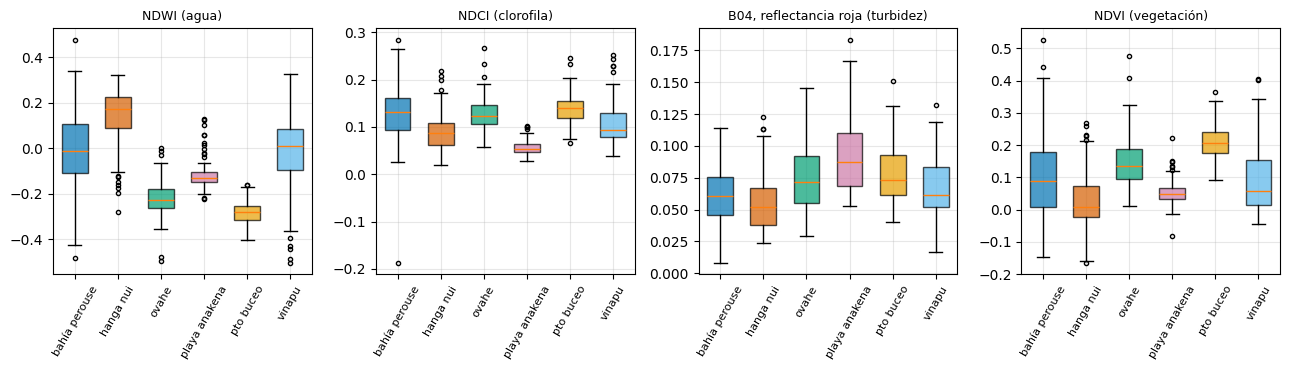

In [57]:
fig, ejes = plt.subplots(1, 4, figsize=(13, 3.8))
orden = list(tabla["id"].unique())
for eje, variable in zip(ejes, VARIABLES):
    datos = [tabla.loc[tabla["id"] == punto, variable].dropna() for punto in orden]
    caja = eje.boxplot(datos, tick_labels=[punto.replace("_", " ") for punto in orden], patch_artist=True, widths=0.6,
                       flierprops={"markersize": 3})
    for parche, color in zip(caja["boxes"], PALETA):
        parche.set_facecolor(color)
        parche.set_alpha(0.7)
    eje.set_title(ETIQUETAS[variable], fontsize=9)
    eje.tick_params(axis="x", rotation=60, labelsize=8)
    eje.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 3. Fechas irregulares y media móvil

Una serie de Sentinel-2 **no es diaria ni regular**. Hay más fechas útiles en verano (menos nubes) que en invierno. Mira cuántas fechas distintas hay por mes (considerando las seis ubicaciones):

In [58]:
fechas_mes = tabla.groupby(tabla["fecha"].dt.to_period("M"))["fecha"].nunique()
validas_mes = tabla.dropna(subset=["ndwi"]).groupby(tabla["fecha"].dt.to_period("M")).size() / tabla["id"].nunique()
cuenta = pd.DataFrame({"fechas con imagen": fechas_mes, "observaciones válidas por punto (promedio)": validas_mes.round(1)})
cuenta

,fechas con imagen,observaciones válidas por punto (promedio)
fecha,,
2023-01,7,3.0
2023-02,5,3.3
2023-03,6,2.0
2023-04,6,3.5
2023-05,6,1.8
2023-06,6,1.8
2023-07,6,2.5
2023-08,6,2.2
2023-09,6,2.7


Los datos limpios son altamente variables debido por la cobertura de nubes en Rapa NUi. Se observa que en ciertos periodos sufren reducciones críticas en el promedio de observaciones válidas por punto

La **media móvil** suaviza el ruido para ver el comportamiento de fondo. `rolling` de pandas acepta una ventana en **días** (`"30D"`, adecuada para fechas irregulares) o en **observaciones** (un número entero); `min_periods` es el mínimo de observaciones que debe haber en la ventana para calcular la media y `center=True` centra la ventana en cada fecha. Compara las dos en la turbidez de la pluma del Biobío:

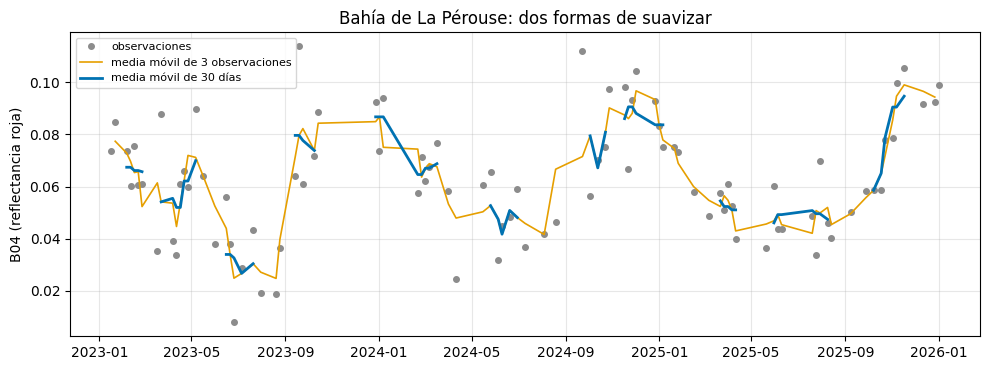

In [59]:
serie_bahía_perouse = tabla[tabla["id"] == "bahía_perouse"].set_index("fecha")["b04"].dropna()
movil_30d = serie_bahía_perouse.rolling("30D", min_periods=3, center=True).mean()  # ventana de 60 días de calendario
movil_3 = serie_bahía_perouse.rolling(3, min_periods=3, center=True).mean()  # ventana de 3 observaciones

fig, eje = plt.subplots(figsize=(10, 3.8))
eje.plot(serie_bahía_perouse.index, serie_bahía_perouse, "o", markersize=4, color="0.55", label="observaciones")
eje.plot(movil_3.index, movil_3, color="#E69F00", linewidth=1.2, label="media móvil de 3 observaciones")
eje.plot(movil_30d.index, movil_30d, color="#0072B2", linewidth=2, label="media móvil de 30 días")
eje.set_ylabel("B04 (reflectancia roja)")
eje.set_title("Bahía de La Pérouse: dos formas de suavizar")
eje.legend(fontsize=8)
eje.grid(alpha=0.3)
plt.tight_layout()
plt.show()

A pesar de ampliar la ventana a 70 días, los saltos persisten debido a los baches prolongados sin datos limpios causados por la nubosidad en esta serie irregular; al haber periodos largos sin observaciones, la entrada de un nuevo punto válido fuerza a la media móvil a ajustarse de manera abrupta.



## 4. Tendencia lineal, y qué puede decir un solo año

`tendencia_lineal` ajusta una recta por mínimos cuadrados contra el tiempo y entrega la pendiente **por año**, el R², el valor p y la recta ajustada. Calculamos la de cada punto y variable:

In [60]:
filas = []
for id_punto in tabla["id"].unique():
    for variable in VARIABLES:
        tendencia = tendencia_lineal(tabla[tabla["id"] == id_punto].set_index("fecha")[variable].dropna())
        filas.append({"punto": id_punto, "variable": variable, "n": tendencia.n,
                      "pendiente_por_año": tendencia.pendiente_anual, "r2": tendencia.r2, "p": tendencia.p_valor})
tendencias = pd.DataFrame(filas)
tendencias.pivot(index="punto", columns="variable", values="pendiente_por_año").round(3)

variable,b04,ndci,ndvi,ndwi
punto,,,,
bahía_perouse,0.004,0.013,0.021,-0.028
hanga_nui,-0.002,0.007,0.008,-0.011
ovahe,-0.004,0.010,0.018,-0.011
playa_anakena,0.001,0.004,0.014,-0.019
pto_buceo,-0.001,0.009,0.022,-0.020
vinapu,-0.003,0.007,0.021,-0.024


El NDWI presenta  tendencias negativas en todos los puntos evaluados, mientras que el NDVI y el NDCI muestran valores positivos muy cercanos a cero, explica un comportamiento interanual estable en la franja costera y marina

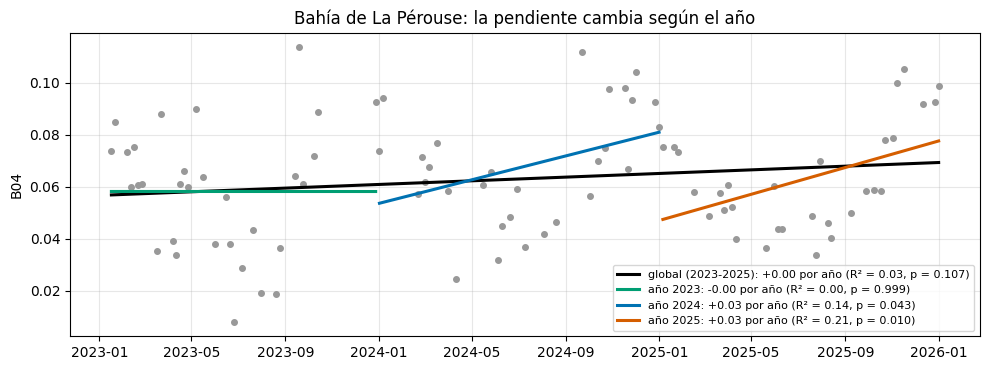

In [63]:
b04_bahia_perouse = tabla[tabla["id"] == "bahía_perouse"].set_index("fecha")["b04"].dropna()

tramos = {
    "global (2023-2025)": (b04_bahia_perouse, "#000000"),
    "año 2023": (b04_bahia_perouse.loc["2023-01-01":"2023-12-31"], "#009E73"),  # Verde
    "año 2024": (b04_bahia_perouse.loc["2024-01-01":"2024-12-31"], "#0072B2"),  # Azul
    "año 2025": (b04_bahia_perouse.loc["2025-01-01":"2025-12-31"], "#D55E00")   # Rojo
}

fig, eje = plt.subplots(figsize=(10, 3.8))
eje.plot(b04_bahia_perouse.index, b04_bahia_perouse, "o", markersize=4, color="0.6")

for nombre, (tramo, color) in tramos.items():
    if len(tramo) >= 3:
        tendencia = tendencia_lineal(tramo)
        eje.plot(tendencia.ajuste.index, tendencia.ajuste, color=color, linewidth=2.2,
                 label=f"{nombre}: {tendencia.pendiente_anual:+.2f} por año (R² = {tendencia.r2:.2f}, p = {tendencia.p_valor:.3f})")

eje.set_ylabel("B04")
eje.set_title("Bahía de La Pérouse: la pendiente cambia según el año")
eje.legend(fontsize=8)
eje.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 5. Patrones estacionales

Lo que **sí** se ve con un año es el ciclo anual: cómo cambia cada variable durante los meses. Calculamos la mediana mensual de cada punto y la dibujamos como mapa de calor.

In [ ]:
meses = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]
nombres_meses = ["ene", "feb", "mar", "abr", "may", "jun", "jul", "ago", "sep", "oct", "nov", "dic"]

# Obtener un mapeo de id a nombre real legible
mapeo_nombres = tabla.groupby("id")["nombre"].first().to_dict()
etiquetas_puntos = [mapeo_nombres[punto] for punto in orden]

fig, ejes = plt.subplots(2, 2, figsize=(12, 6), sharex=True)
for eje, variable in zip(ejes.ravel(), VARIABLES):
    # Se calcula la mediana agrupando por mes considerando la totalidad de los tres años
    mediana_mes = tabla.groupby(["id", tabla["fecha"].dt.month])[variable].median().unstack().reindex(columns=meses)
    mediana_mes = mediana_mes.loc[orden]

    imagen = eje.imshow(mediana_mes.values, aspect="auto", cmap="viridis")
    eje.set_yticks(range(len(orden)), labels=etiquetas_puntos, fontsize=8)
    eje.set_xticks(range(12), labels=nombres_meses, fontsize=8)
    eje.set_title(f"{ETIQUETAS[variable]} (Climatología 2023-2025)", fontsize=9)
    plt.colorbar(imagen, ax=eje, fraction=0.04)

plt.tight_layout()
plt.show()

Y la climatología mensual de **un** punto: agrupamos las observaciones por mes y calculamos media, desviación y número de observaciones de cada mes. La barra de error es una desviación estándar. Mira la columna `n`.

In [ ]:
por_mes = serie_bahía_perouse.groupby(serie_bahía_perouse.index.month.rename("mes"))
clima_bahia = por_mes.agg(media="mean", desv="std", n="size").reindex(range(1, 13))
print(clima_bahia.round(3).T.to_string())

orden_meses = clima_bahia.reindex(meses)
fig, eje = plt.subplots(figsize=(9, 3.6))
eje.errorbar(range(12), orden_meses["media"], yerr=orden_meses["desv"], fmt="o-", color="#0072B2", capsize=3)
eje.set_xticks(range(12), labels=nombres_meses)
eje.set_ylabel("B04 (media mensual ± 1 desviación)")
eje.set_title("Bahía de La Pérouse: ciclo de un año")
eje.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 6. Anomalías con un año de datos: z-score

Una **anomalía** es un valor que se aleja de lo esperado. El z-score la mide en desviaciones estándar: `z = (valor - media) / desviación`. Un |z| mayor que 2 es poco habitual. Hay dos formas de definir "lo esperado":

* `referencia="mes"`: la media y la desviación **del mismo mes del año**. Quita el ciclo estacional (un valor de enero se compara con enero), pero necesita muchos años.
* `referencia="total"`: la media y la desviación **de toda la serie**. Mezcla estación con anomalía.

Con un año de datos, cada mes tiene entre 2 y 11 observaciones, todas del mismo año. Veamos qué pasa con B04, contando las fechas con |z| > 2 con cada referencia:

In [ ]:
filas = []
for id_punto in tabla["id"].unique():
    serie = tabla[tabla["id"] == id_punto].set_index("fecha")["b04"].dropna()
    z_total = anomalias_zscore(serie, referencia="total")
    z_mes = anomalias_zscore(serie, referencia="mes")
    filas.append({"punto": id_punto, "n": len(serie), "|z| > 2 con 'total'": int((z_total.abs() > 2).sum()),
                  "|z| > 2 con 'mes'": int((z_mes.abs() > 2).sum()),
                  "z máximo 'total'": round(z_total.max(), 1), "z máximo 'mes'": round(z_mes.max(), 1)})
pd.DataFrame(filas).set_index("punto")

Lo más adecuado es utilizar referencia="total" Es mucho más sensible cuando la serie es corta.

Es intuitivo y fácil de explicar en un reporte.

Su única "contra" es que la estacionalidad se cuela (los valores más altos coincidirán con la época del año en que naturalmente sube la turbidez o el índice evaluado). Las verdaderas anomalías libres de estacionalidad solo pueden calcularse cuando se cuenta con registros históricos largos (de varias décadas)

Calculamos el z-score de B04 en la pluma del Biobío y marcamos las fechas con |z| > 2:

In [ ]:
z_bahía = anomalias_zscore(serie_bahía_perouse, referencia="total")
raras = z_bahía[z_bahía.abs() > 2]

fig, ejes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
ejes[0].plot(serie_bahía_perouse.index, serie_bahía_perouse, "o-", color="0.6", markersize=3, linewidth=0.8)
ejes[0].plot(raras.index, serie_bahía_perouse[raras.index], "o", color="#D55E00", markersize=7, label="|z| > 2")
ejes[0].set_ylabel("B04")
ejes[0].legend(fontsize=8)
ejes[1].bar(z_bahía.index, z_bahía, width=2, color=np.where(z_bahía.abs() > 2, "#D55E00", "0.6"))
ejes[1].axhline(2, color="k", linewidth=0.7, linestyle="--")
ejes[1].set_ylabel("z (referencia total)")
for eje in ejes:
    eje.grid(alpha=0.3)
ejes[0].set_title("Bahía de La Pérouse: turbidez y fechas atípicas")
plt.tight_layout()
plt.show()

Una fecha atípica **no es todavía un evento**. Antes de interpretar, mira qué hay detrás: ¿cuánta nube tenía la escena y qué fracción de la ventana pasó la máscara? Un valor atípico con pocos píxeles válidos o con mucha nube en la escena es sospechoso.

In [ ]:
# Filtra la tabla original exclusivamente para Bahía de La Pérouse en las fechas atípicas (|z| > 2)
# Selecciona columnas clave: fecha, b04, nubes_escena y pixeles_validos
revision = tabla[(tabla["id"] == "bahía_perouse") & tabla["fecha"].isin(raras.index)][["fecha", "b04", "nubes_escena", "pixeles_validos"]]
revision = revision.assign(z=raras.values)
revision.round({"b04": 3, "nubes_escena": 1, "pixeles_validos": 2, "z": 1})

## 7. Preparando el bloque 7: climatología y anomalías con Landsat
Aquí al no tenemos datos de Landsat para temperatura

In [ ]:
# Filtramos la serie limpia de NDWI para Bahía de La Pérouse y la asignamos a 'st'
st = tabla[tabla["id"] == "bahía_perouse"].set_index("fecha")["ndwi"].dropna()

# Calculamos el promedio y desviación mensual usando como base los datos de Sentinel-2 (2024-2025)
base = st.loc["2024":"2025"]
clima_st = base.groupby(base.index.month.rename("mes")).agg(media="mean", desv="std", n="size").reindex(range(1, 13))
print("Observaciones por mes en la base de Sentinel-2:", int(clima_st["n"].min()), "a", int(clima_st["n"].max()))

fig, eje = plt.subplots(figsize=(8, 3.6))
eje.fill_between(range(1, 13), clima_st["media"] - clima_st["desv"], clima_st["media"] + clima_st["desv"], alpha=0.25, color="#0072B2")
eje.plot(range(1, 13), clima_st["media"], "o-", color="#0072B2")
eje.set_xticks(range(1, 13), labels=["ene", "feb", "mar", "abr", "may", "jun", "jul", "ago", "sep", "oct", "nov", "dic"])
eje.set_ylabel("NDWI (agua)")
eje.set_title("Ciclo mensual de NDWI en Bahía de La Pérouse (Sentinel-2, ± 1 desviación)")
eje.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Ahora sí funciona `referencia="mes"`: el z-score compara cada observación con el mismo mes de los 12 años de la base. Mostramos el promedio mensual de esas anomalías desde 2022. Los meses **sin barra** no tienen ninguna observación sin nubes: **un mes sin dato no es "anomalía cero"**, es un vacío.

In [ ]:
# Filtramos la serie limpia de NDWI para Bahía de La Pérouse
ndwi_bahia = tabla[tabla["id"] == "bahía_perouse"].set_index("fecha")["ndwi"].dropna()

# Calculamos el z-score con referencia mensual utilizando la base real del estudio (2023-2025)
z_st = anomalias_zscore(ndwi_bahia, referencia="mes", base=(2023, 2025))
z_mensual = z_st.resample("MS").mean()

fig, eje = plt.subplots(figsize=(11, 3.6))
eje.bar(z_mensual.index, z_mensual.fillna(0), width=25, color=np.where(z_mensual.fillna(0) >= 0, "#D55E00", "#0072B2"))
for mes in z_mensual.index[z_mensual.isna()]:
    eje.axvspan(mes, mes + pd.offsets.MonthBegin(1), color="0.85", label="mes sin observación válida")
manijas, nombres = eje.get_legend_handles_labels()
eje.legend(dict(zip(nombres, manijas)).values(), dict(zip(nombres, manijas)).keys(), fontsize=8, loc="upper left")
eje.axhline(0, color="k", linewidth=0.7)
eje.set_ylabel("anomalía mensual (z)")
eje.set_title("Bahía de La Pérouse: Anomalía mensual de NDWI respecto a la climatología")
eje.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("Anomalía media mensual (z), NaN = sin observación válida:")
print(z_mensual.round(2).to_string())

## 8. Interpretación

Volvemos a la serie de Sentinel-2 con tres preguntas. Para cada una, los números salen de los datos y la lectura es **una hipótesis**: aquí no tenemos lluvia, caudal ni mediciones de clorofila en terreno, que es lo que haría falta para confirmarlas.


In [ ]:
# 1. Definimos los sitios de estudio oficiales de Rapa Nui
sitios_rapa_nui = ["bahía_perouse", "hanga_nui", "ovahe", "playa_anakena", "pto_buceo", "vinapu"]

# 2. Calculamos la mediana mensual de la turbidez (B04) para los sitios seleccionados
mensual_b04 = (
    tabla[tabla["id"].isin(sitios_rapa_nui)]
    .assign(mes=lambda d: d["fecha"].dt.to_period("M"))
    .pivot_table(index="mes", columns="id", values="b04", aggfunc="median")
)

# 3. Conteo de observaciones válidas para un sitio de referencia (ej. Bahía de La Pérouse)
n_b04 = (
    tabla.dropna(subset=["b04"])
    .query("id == 'bahía_perouse'")
    .groupby(tabla["fecha"].dt.to_period("M"))
    .size()
    .rename("n_bahia_perouse")
)

# 4. Consolidamos la tabla final limpia
pd.concat([mensual_b04.round(3), n_b04], axis=1)

## Cierre

* Mira siempre **más de un estadístico** (media, mediana, percentiles) y **cuántos datos** hay detrás.
* Con fechas irregulares usa ventanas en **días** y exige un mínimo de observaciones.
* Una **tendencia** de un año mezcla estación y cambio: no la uses para concluir.
* Una **anomalía** necesita una climatología con varios años; con un año usa la referencia total y desconfía de los z extremos hasta mirar la imagen.
* Un **vacío** de datos no es un cero.

En el bloque 6 hacemos estos gráficos interactivos. En el 7 usamos la serie de TSM de décadas para detectar eventos extremos.